In [1]:
!pip install --upgrade numba librosa

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import glob

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# biblioteca para trabalhar com áudio
import librosa
import librosa.display

In [5]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix

In [9]:
path = '/content/drive/MyDrive/ai-mechanic-export'
path_train = os.path.join(path, 'training')
path_test = os.path.join(path, 'testing')


In [16]:
train_files = glob.glob(os.path.join(path_train, '*.wav'))
test_files = glob.glob(os.path.join(path_test, '*.wav'))

ok_signals_amount = 80
nok_signals_amount = 20

In [11]:
# gera a quantidade desejada de áudios ok e não ok
ok_signals = [f for f in train_files if 'air leak' not in f.lower()]
nok_signals = [f for f in train_files if 'air leak' in f.lower()]

In [15]:
# transforma o áudio recebido em um espectograma mel
def create_spectrogram(path):
  audio, sr = librosa.load(path, sr=22050)
  spec = librosa.feature.melspectrogram(y=audio, sr=sr, n_mels=128)
  spec_db = librosa.power_to_db(spec, ref=np.max)
  signature = np.mean(spec_db, axis=1)
  return signature, spec_db

In [14]:
# separa áudios ok para treinar o detector de anomalias (se especializar no OK)
X_normal_train = []
for file in ok_signals:
  features, _, _ = create_spectrogram(file)
  X_normal_train.append(features)

# separação dos áudios não ok para teste
#X_test_nok = np.array([create_spectrogram(audio, sr)[0] for audio, sr in nok_signals])
# separação dos áudios ok para teste
#X_test_ok = X_normal_train[:20]
# separação dos áudios misturados (ok e não ok) para teste
all_files = test_files + nok_signals

X_test_ok_nok = []
for file in all_files:
  features, _, _ = create_spectrogram(file)
  X_test_ok_nok.append(features)


ValueError: too many values to unpack (expected 2)

In [ ]:
# construímos um gabarito do que seria a resposta correta do detector de anomalia (1=normal,-1=anormal)
y_real = np.array([1]*len(X_test_ok) + [-1]*len(X_test_nok))
display(y_real)

array([ 1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1])

In [ ]:
# treina o modelo com o algoritmo de Isolation Forest apenas com dados normais
model = IsolationForest(contamination=0.05, random_state=42)
model.fit(X_normal_train)

IsolationForest(contamination=0.05, random_state=42)

In [ ]:
predict = model.predict(X_test_ok_nok)
print("Resultado da Classificação (1=normal,-1=anormal)")
print(classification_report(y_real, predict))

Resultado da Classificação (1=normal,-1=anormal)
              precision    recall  f1-score   support

          -1       0.83      0.25      0.38        20
           1       0.56      0.95      0.70        20

    accuracy                           0.60        40
   macro avg       0.70      0.60      0.54        40
weighted avg       0.70      0.60      0.54        40



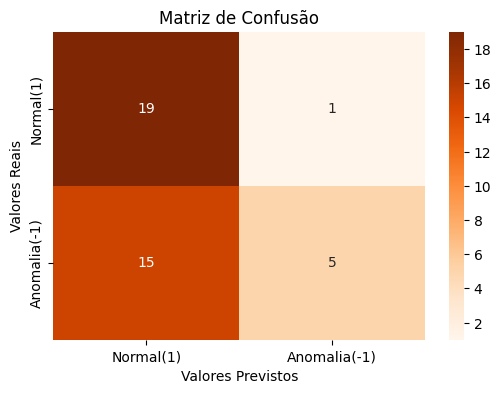

In [ ]:
matrix = confusion_matrix(y_real, predict, labels=[1, -1])
plt.figure(figsize=(6,4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Normal(1)','Anomalia(-1)'],
            yticklabels=['Normal(1)','Anomalia(-1)'])
plt.title('Matriz de Confusão')
plt.ylabel('Valores Reais')
plt.xlabel('Valores Previstos')
plt.show()